In [1]:
import sys
import aperturePhot as ap
from photutils.aperture import CircularAperture
from pathlib import Path
from astropy.nddata import CCDData
from astropy.io import fits
import numpy as np
import matplotlib.pyplot as plt
import os
import plateSolve
%matplotlib inline
from photutils.detection import find_peaks
from astropy.table import Table
from astropy.stats import sigma_clipped_stats
from astropy.nddata import NDData
from photutils.psf import extract_stars
from photutils.psf import EPSFBuilder
from astropy.visualization import simple_norm
from photutils.detection import IRAFStarFinder
from photutils.psf import IntegratedGaussianPRF, DAOGroup
from photutils.background import MMMBackground, MADStdBackgroundRMS
from astropy.modeling.fitting import LevMarLSQFitter
from astropy.stats import gaussian_sigma_to_fwhm
from photutils.psf import IterativelySubtractedPSFPhotometry
import astropy.wcs as wcs

datadir = '/home/neo/Astro_Lab/Data/Stacked_Images/'
path = Path(datadir)
os.chdir(path)

In [3]:
red = 'light_NGC7089_R.fit'
green = 'light_NGC7089_V.fit'

imgR = CCDData.read(red)
imgV = CCDData.read(green)
#ap.showimage(imgR)
#ap.showimage(imgV)

x1,x2,y1,y2 = 155,915,130,950
crop_R = imgR[y1:y2,x1:x2]
crop_V = imgV[y1:y2,x1:x2]
#ap.showimage(crop_R)
#ap.showimage(crop_V)

crop_R.data = crop_R.data * 15
crop_V.data = crop_V.data * 16

crop_R.write('light_NGC7089_R_new.fit',overwrite=True)
crop_V.write('light_NGC7089_V_new.fit',overwrite=True)


INFO: first HDU with data is extension 1. [astropy.nddata.ccddata]
INFO: first HDU with data is extension 1. [astropy.nddata.ccddata]


In [4]:
red = 'light_NGC7089_R_new.fit'
green = 'light_NGC7089_V_new.fit'

imgR = CCDData.read(red)
imgV = CCDData.read(green)

x_corr = [466,728,649]
y_corr = [775,640,67]

stars_tbl = Table()
stars_tbl['x'] = x_corr  
stars_tbl['y'] = y_corr

In [5]:
#Backgraoud Substraction:

sources_R,bgplane_R = ap.findStars(imgR,bgorder=1)
sources_V,bgplane_V = ap.findStars(imgV,bgorder=1)

imgR.data = imgR.data - bgplane_R
imgV.data = imgV.data - bgplane_V

#ap.showimage(imgR)


['id', 'xcentroid', 'ycentroid', 'sharpness', 'roundness1', 'roundness2', 'npix', 'sky', 'peak', 'flux', 'mag']
['id', 'xcentroid', 'ycentroid', 'sharpness', 'roundness1', 'roundness2', 'npix', 'sky', 'peak', 'flux', 'mag']


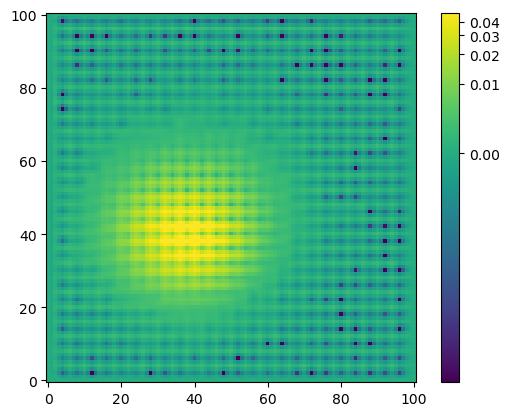

In [6]:
nddata_R = NDData(data=imgR.data) 
nddata_V = NDData(data=imgV.data)

stars_R = extract_stars(nddata_R, stars_tbl, size=25)  
stars_V = extract_stars(nddata_V, stars_tbl, size=25) 

epsf_builder = EPSFBuilder(oversampling=4, maxiters=3,progress_bar=False)  

epsf_R, fitted_stars_R = epsf_builder(stars_R)
epsf_V, fitted_stars_V = epsf_builder(stars_V)  

norm = simple_norm(epsf_V.data, 'log', percent=99.)
plt.imshow(epsf_V.data, norm=norm, origin='lower', cmap='viridis')
plt.colorbar()


In [7]:
sigma_psf = 2.0
bkgrms = MADStdBackgroundRMS()
std = bkgrms(imgR)
iraffind_R = IRAFStarFinder(threshold=3.5*std,fwhm=sigma_psf * gaussian_sigma_to_fwhm,minsep_fwhm=0.01, roundhi=5.0, roundlo=-5.0,sharplo=0.0, sharphi=2.0)
#iraffind = IRAFStarFinder(threshold=3.5*std,fwhm=12,minsep_fwhm=0.01, roundhi=5.0, roundlo=-5.0,sharplo=0.0, sharphi=2.0)

daogroup = DAOGroup(2.0 * sigma_psf * gaussian_sigma_to_fwhm)
#daogroup = DAOGroup(2.0 * 12)
mmm_bkg = MMMBackground()
fitter = LevMarLSQFitter()

photometry_R = IterativelySubtractedPSFPhotometry(finder=iraffind_R,group_maker=daogroup,bkg_estimator=mmm_bkg,psf_model=epsf_R,fitter=LevMarLSQFitter(),niters=1, fitshape=(11, 11))
result_tab_R = photometry_R(image=imgR.data)


In [21]:

x_V = result_tab_R['x_0']
y_V = result_tab_R['y_0']
pos_R = Table(names=['x_0','y_0'],data=[x_V,y_V])

epsf_R.x_0.fixed = True
epsf_R.y_0.fixed = True

stdV = bkgrms(imgV.data)
iraffind_V = IRAFStarFinder(threshold=3.5*stdV,fwhm=sigma_psf * gaussian_sigma_to_fwhm,minsep_fwhm=0.01, roundhi=5.0, roundlo=-5.0,sharplo=0.0, sharphi=2.0)
#iraffind = IRAFStarFinder(threshold=3.5*std,fwhm=12,minsep_fwhm=0.01, roundhi=5.0, roundlo=-5.0,sharplo=0.0, sharphi=2.0)
daogroup = DAOGroup(2.0 * sigma_psf * gaussian_sigma_to_fwhm)
#daogroup = DAOGroup(2.0 * 12)

photometry_V = IterativelySubtractedPSFPhotometry(finder=iraffind_V,group_maker=daogroup,bkg_estimator=mmm_bkg,psf_model=epsf_R,fitter=LevMarLSQFitter(),niters=1, fitshape=(11, 11))
result_tab_V = photometry_V(image=imgV.data,init_guesses=pos_R)


In [39]:
d_frames_R = result_tab_R.to_pandas()
d_frames_V = result_tab_V.to_pandas()

print(d_frames_R['flux_0'][0:5])
print(d_frames_V['flux_0'][0:5])

0    3.180084e+04
1    1.448173e+05
2    6.181624e+04
3    5.611399e+06
4    5.159425e+04
Name: flux_0, dtype: float64
0    2.192618e+04
1    9.121440e+04
2    4.745600e+04
3    3.009832e+06
4    5.188675e+04
Name: flux_0, dtype: float64


In [40]:
#Cooordinate Trnasformation (x,y -> ra,dec)

hduR = fits.open(red)
hduV = fits.open(green)

wcsR = wcs.WCS(hduR[0].header)
wcsV = wcs.WCS(hduV[0].header)

print(d_frames_R['flux_0'][0:5])
print(d_frames_V['flux_0'][0:5])

Rstarxy = np.transpose((d_frames_R['x_0'],d_frames_R['y_0']))
radec = wcsR.all_pix2world(Rstarxy,1)


d_frames_R = d_frames_R.assign(RA = radec[:,0])
d_frames_R = d_frames_R.assign(DEC = radec[:,1])

d_frames_V = d_frames_V.assign(RA = radec[:,0])
d_frames_V = d_frames_V.assign(DEC = radec[:,1])


#Flux to Magnitude Transformation (flux to mag)

m_0 = 10
mag_R = m_0 - 2.5*np.log10(d_frames_R['flux_0'])
err_R = 2.5*np.abs(d_frames_R['flux_unc']/(d_frames_R['flux_0']*np.log(10)))

mag_V = m_0 - 2.5*np.log10(d_frames_V['flux_0'])
err_V = 2.5*np.abs(d_frames_V['flux_unc']/(d_frames_V['flux_0']*np.log(10)))

d_frames_R = d_frames_R.assign(mag = mag_R)
d_frames_R = d_frames_R.assign(err = err_R)

d_frames_V = d_frames_V.assign(mag = mag_V)
d_frames_V = d_frames_V.assign(err = err_V)

#print(mag_R[0:10])
#print(mag_V[0:10])
#print(d_frames_R['flux_0'][0:10])
#print(d_frames_V['flux_0'][0:10])

# Add Airmass to data frames

airmass_R = hduR[0].header['AIRMASS']
airmass_R = np.repeat(airmass_R,len(d_frames_R['id']))

airmass_V = hduV[0].header['AIRMASS']
airmass_V = np.repeat(airmass_V,len(d_frames_V['id']))

d_frames_R = d_frames_R.assign(airmass = airmass_R)
d_frames_V = d_frames_V.assign(airmass = airmass_V)

print(d_frames_R['flux_0'][0:5])
print(d_frames_V['flux_0'][0:5])

d_frames_R.to_csv("R_band.csv",index=True)
d_frames_V.to_csv("V_band.csv",index=True)





0    3.180084e+04
1    1.448173e+05
2    6.181624e+04
3    5.611399e+06
4    5.159425e+04
Name: flux_0, dtype: float64
0    2.192618e+04
1    9.121440e+04
2    4.745600e+04
3    3.009832e+06
4    5.188675e+04
Name: flux_0, dtype: float64
0    3.180084e+04
1    1.448173e+05
2    6.181624e+04
3    5.611399e+06
4    5.159425e+04
Name: flux_0, dtype: float64
0    2.192618e+04
1    9.121440e+04
2    4.745600e+04
3    3.009832e+06
4    5.188675e+04
Name: flux_0, dtype: float64


/home/neo/mambaforge/envs/ENVp3.9/lib/python3.9/site-packages/pandas/core/arraylike.py:402: RuntimeWarning: invalid value encountered in log10
  result = getattr(ufunc, method)(*inputs, **kwargs)
